In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

We are going to train a neural network to predict the **30-day volatility of SAN.MC**.

1. **Phase 1: Dataset Preparation and Indicators:** Data cleaning, calculation of returns, rolling volatility, and technical indicators (such as RSI and VIX).
2. **Phase 2: Preprocessing and Chronological Split (60% / 20% / 20%):**
   - **Train Set (60%):** Initial chronological data used to fit the network weights.
   - **Validation Set (20%):** Intermediate data used for hyperparameter tuning and controlling overfitting.
   - **Test Set (20%):** Isolated dataset left untouched during development, used for the final evaluation of the model in a real-world scenario.
   - **Data Scaling:** Feature normalization to the range $[0, 1]$ fitted exclusively on training data.
   - **Time Windows:** Construction of three-dimensional tensors $(N, 60, 8)$ to train the neural network.
3. **Phase 3: Building, Optimization, and Training of the LSTM:** Selection of the optimal architecture using the final Training set (Train + Validation).
4. **Phase 4: Evaluation on the Test Set and Visualization:** Reversing the scaling, generating real-world predictions, and analyzing error metrics ($MSE$, $RMSE$, $MAE$).

In [2]:
#First, we download the data from Yahoo Finance

tickers = ['SAN.MC', '^VIX', '^GSPC']
start_date = '2018-01-01'
end_date = '2026-01-01'

print('Downloading data from the market...')

raw_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust = True)['Close']

print('\nData succesfully downloaded')

raw_data = raw_data.ffill().dropna()

Descargando datos del mercado...


[*********************100%***********************]  3 of 3 completed


Datos descargados con éxito.


In [3]:
#Now we construct our dataframe
df = pd.DataFrame()
df['SAN_Close'] = raw_data['SAN.MC']
df['VIX_Close'] = raw_data['^VIX']
df['SP500_Close'] = raw_data['^GSPC']

#We calculate logaritihms returns
df['SAN_Returns'] = np.log(df['SAN_Close']/df['SAN_Close'].shift(1))
df['SP500_Returns'] = np.log(df['SP500_Close']/df['SP500_Close'].shift(1))

#We define the TARGET to predict: 30-days volatility
df['Target_Vol_30d'] = df['SAN_Returns'].rolling(window = 30).std() * np.sqrt(252)

#Additional features: 10-days volatility and 14-days Relative Strength Index (RSI)
df['SAN_Vol_10d'] = df['SAN_Returns'].rolling(window = 10).std() * np.sqrt(252)

delta = df['SAN_Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain/loss
df['SAN_RSI_14d'] = 100-(100/(1+rs))


#We clean again the dataset and show some rows
dataset = df.dropna()


print(f"Dimensions of the final table: {dataset.shape[0]} filas x {dataset.shape[1]} columnas")
print("\nVPreview of the first 5 rows of the dataset:")
dataset.head()

Dimensiones de la tabla final: 2037 filas x 8 columnas

Vista previa de las primeras 5 filas del dataset:


,SAN_Close,VIX_Close,SP500_Close,SAN_Returns,SP500_Returns,Target_Vol_30d,SAN_Vol_10d,SAN_RSI_14d
Date,,,,,,,,
2018-02-13,3.974884,24.969999,2662.939941,-0.018993,0.002610,0.232573,0.285149,-81.510829
2018-02-14,3.987950,19.260000,2698.629883,0.003282,0.013313,0.232714,0.277417,-55.394034
2018-02-15,4.005371,19.129999,2731.199951,0.004359,0.011997,0.211910,0.284927,-65.356960
2018-02-16,4.075780,19.459999,2732.219971,0.017426,0.000373,0.217281,0.306600,-110.214151
2018-02-19,4.055456,19.459999,2732.219971,-0.004999,0.000000,0.217552,0.302847,-119.184967


Before continuing, we make sure that our data has only valid entries

In [4]:
print('¿Are there infinite values or NaN?: ', dataset.isin([np.inf,-np.inf]).any().any() or dataset.isna().any().any())

¿Hay valores infintos o NaN?:  True


There are, let us remove them.

In [5]:
dataset = dataset.replace([np.inf, -np.inf], np.nan)
dataset = dataset.dropna()
print('¿Are there infinite values or NaN?: ', dataset.isin([np.inf,-np.inf]).any().any() or dataset.isna().any().any())

¿Hay valores infintos o NaN?:  False


Everything looks good now. To continue, we will divide our dataset into three parts: training set (60%), validation set (20%), and test set (20%). The test set will not be touched under **any** circumstances (only when the neural network is fully trained). To determine which hyperparameters to select for training our neural network (number of epochs, number of nodes, and other training strategies), we will train the neural network on the training set and then evaluate its performance on the validation set. The setup that yields the best performance will be selected, and we will then train the neural network using those chosen hyperparameters on the combined training and validation sets. Finally, we will verify whether the neural network predicts acceptably on the test set.

The training set gathers the first 60% in chronological order, the validation set takes the following 20%, and the test set covers the final 20%. This chronological split is necessary because, otherwise, the training set would have access to future data, making the test set useless.

In [6]:
dataset_len = len(dataset)
train_df = dataset.iloc[:int(dataset_len * 0.6)]
val_df = dataset.iloc[int(dataset_len * 0.6):int(dataset_len * 0.8)]
test_df = dataset.iloc[int(dataset_len * 0.8):]
print(f"Training rows: {len(train_df)}")
print(f"Validation rows: {len(val_df)}")
print(f"Testing rows: {len(test_df)}")

Filas para Training: 1221
Filas para Validation: 407
Filas para Testing: 408


If one column has very high values and another has very low values—as can happen, for instance, with the SP500_Close column (which can be very high) and SAN_Returns (which will be much lower)—the neural network will assign significantly more weight to the higher-valued feature. To resolve this issue, we will scale the data using the following formula: $$x_{\text{scaled}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}$$
We previously ensured there are no infinite values in the dataset, so the maximum and minimum values are guaranteed to be well-defined.

In [7]:
#DATA SCALING
# We fit the Scaler exclusively on the training set so that the model does not have access to the maximum and minimum values of the test set (to prevent data leakage)
scaler = MinMaxScaler(feature_range = (0,1))

train_scaled = scaler.fit_transform(train_df)
val_scaled = scaler.transform(val_df)
test_scaled = scaler.transform(test_df)


target_scaler = MinMaxScaler(feature_range = (0,1))
target_scaler.fit(train_df[['Target_Vol_30d']])


,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](1,)",[0.94]
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](1,)",[0.14]
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](1,)",[0.8]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Target_Vol_30d']
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](1,)",[-0.18]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,1221


Our neural network will not read rows independently; instead, it will process data in blocks of 60 days. In theory, the neural network will detect patterns and learn more by watching the full sequence of prior days rather than analyzing each day in isolation. This creates a three-dimensional structure in the following sense: the original dataset is a two-dimensional table (rows and columns), and by converting each sample into a 60-day window, we add a third dimension—time. Thus, the neural network processes and learns from the data in three dimensions.

In [8]:
#CREATE TIME WINDOWS
def create_sequences(data, target_col_idx, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, :])
        y.append(data[i, target_col_idx])
    return np.array(X), np.array(y)

target_col_idx = dataset.columns.get_loc('Target_Vol_30d')
lookback = 60
X_train, y_train = create_sequences(train_scaled, target_col_idx, lookback)
X_val, y_val = create_sequences(val_scaled, target_col_idx, lookback)
X_test, y_test = create_sequences(test_scaled, target_col_idx, lookback)



print("--- Dimensiones de la estructura tridimensional de los datos ---")
print(f"X_train shape: {X_train.shape} )
print(f"y_train shape: {y_train.shape} )
print(f"X_val shape: {X_val.shape})
print(f"y_val shape: {y_val.shape})
print(f"X_test shape:  {X_test.shape} )
print(f"y_test shape:   {y_test.shape})

--- Dimensiones de la estructura tridimensional de los datos ---
X_train shape: (1161, 60, 8) -> (Ventanas, 60 días pasados, 8 variables)
y_train shape: (1161,) -> (Ventanas, Target del día 61)
X_val shape: (347, 60, 8) -> (Ventanas, 60 días pasados, 8 variables)
y_val shape: (347,) -> (Ventanas, Target del día 61)
X_test shape:  (348, 60, 8) -> (Ventanas, 60 días pasados, 8 variables)
y_test shape:   (348,) -> (Ventanas, Target del día 61)


Now we are going to build, optimize, and train our **neural network**.

#### **Step 1: Hyperparameter Optimization**
- We will train the model using the **Training set** and evaluate its loss on the **Validation set**.
- We will use the **Early Stopping** technique, monitoring the validation loss. This will give us the exact number of epochs the network needs before it begins to overfit.
- We will validate parameters such as **learning rate**, **dropout rate**, and layer density.

First, we will design a function to build our neural network. It will feature two stacked LSTM layers with Dropout to prevent overfitting, followed by a dense layer with a ReLU activation function (to introduce non-linearity), and a final output node that generates the prediction.

We will use the Adam optimizer for training along with Mean Squared Error (MSE) as the loss function.

In [9]:
#We fix the random seeds
tf.random.set_seed(13)
np.random.seed(13)


time_steps = X_train.shape[1] #en este caso 60 días
n_features = X_train.shape[2] #en este caso 8 columnas

# units_1 -> number of neurons for the first layer
# units_2 -> number of neurons for the second layer
# units_dense -> number of neurons for the dense layer
def create_neural_network(units_1, units_2, units_dense, dropout_rate, learning_rate):
    model = Sequential([
        Input(shape=(time_steps, n_features)),
        #First layer
        LSTM(units = units_1, return_sequences = True),
        #We randomly shut off some nodes (Dropout)
        Dropout(dropout_rate),
        #Second layer
        LSTM(units = units_2, return_sequences = False),
        Dropout(dropout_rate),
        #Dense layer
        Dense(units = units_dense, activation = 'relu'),
        #Output
        Dense(units = 1, activation = 'linear')
    ])
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate = learning_rate),
        loss = 'mean_squared_error',
        metrics = ['mean_absolute_error']
    )
    return model

Next, we will find the optimal number of epochs for a neural network with a first layer of 60 neurons, a second layer of 30, a dense layer of 14, a dropout rate of 0.2, and a learning rate of 0.001. To find the optimal number of epochs, we will set a maximum of 60 epochs and keep the number that achieves the best performance on the validation set. Additionally, if the validation loss does not decrease after 10 iterations, training will stop early (**early stopping**). We will also use a batch size of 30 during training.

Throughout the training process, the validation errors for each epoch will be displayed.

Next, we will extract the epoch that produced the lowest validation loss (`val_loss`). This will be the number of epochs used when retraining the neural network on the combined Training and Validation sets (80%) before evaluating its final performance on the Test set.

To calculate the best number of epochs, we will subtract the patience (10 in this case) from the total number of executed epochs. Since neural network training is subject to randomness, we will run the training process multiple times and take the median of the optimal epochs.

In [10]:
N = 5
l_epochs = []
for i in range(N):
    
    model_tune = create_neural_network(60, 30, 15, 0.2, 0.001)
        
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )
    
    history_tune = model_tune.fit(
        X_train, y_train,
        epochs=60,
        batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        verbose=1
    )
    best_epochs = len(history_tune.history['loss']) - early_stop.patience
    if best_epochs <= 0:
        best_epochs = len(history_tune.history['loss'])  

    l_epochs.append(best_epochs)
    print(f"Iteration {i+1}/{N} -> Optimal detectec epochs: {best_epochs}")




Epoch 1/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0202 - mean_absolute_error: 0.1003 - val_loss: 0.0040 - val_mean_absolute_error: 0.0477
Epoch 2/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0071 - mean_absolute_error: 0.0612 - val_loss: 0.0023 - val_mean_absolute_error: 0.0371
Epoch 3/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0052 - mean_absolute_error: 0.0519 - val_loss: 0.0016 - val_mean_absolute_error: 0.0329
Epoch 4/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0049 - mean_absolute_error: 0.0511 - val_loss: 0.0018 - val_mean_absolute_error: 0.0305
Epoch 5/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0041 - mean_absolute_error: 0.0448 - val_loss: 0.0014 - val_mean_absolute_error: 0.0278
Epoch 6/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0042 - mean_absolute_error: 0.0463 - val_loss: 0.0015 - val_mean_absolute_error: 0.0294
Epoch 7/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0035 - mean_absolute_error: 0.0426 - val_loss

In [11]:
print(l_epochs)
best_epochs = int(np.median(l_epochs))
print(f"\n Median of optimal number of epochs: {best_epochs}")

[50, 24, 23, 22, 30]

 Epochs óptimos detectados tras tomar la mediana: 24


#### **Step 2: Final Retraining (Train + Validation = 80%)**
- Once the optimal hyperparameters have been determined (in our case, choosing the previously mentioned neural network architecture and the optimal number of epochs identified during training), **we will combine the training and validation sets** into a single three-dimensional dataset (80% of the total historical data).
- We will retrain an identical model from scratch using this expanded dataset for the computed optimal number of epochs. This allows the network to learn from the most recent financial patterns before being evaluated on the Test set.

In [12]:
# We combine the Training set with the Validation set to create the full training set (80%). We concatenate them along axis = 0 to join them row-wise.
X_train_full = np.concatenate((X_train, X_val), axis = 0)
y_train_full = np.concatenate((y_train, y_val), axis = 0)

final_model = create_neural_network(60, 30, 15, 0.2, 0.001)

history_final = final_model.fit(
    X_train_full, y_train_full,
    epochs=best_epochs,
    batch_size=32,
    verbose=1
)

Epoch 1/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0127 - mean_absolute_error: 0.0788
Epoch 2/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0050 - mean_absolute_error: 0.0511
Epoch 3/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0037 - mean_absolute_error: 0.0423
Epoch 4/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0036 - mean_absolute_error: 0.0427
Epoch 5/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0030 - mean_absolute_error: 0.0380
Epoch 6/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0032 - mean_absolute_error: 0.0389
Epoch 7/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0029 - mean_absolute_error: 0.0369
Epoch 8/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0025 - mean_absolute_error: 0.0357
Epoch 9/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0023 - mean_absolute_error: 0.0341
Epoch 10/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0022 - mean_absolute_error: 0.0326
Epoch 11/24
48/48 ━━━━━━━━━━━━━━━━━━━━ 

We generate predictions and then reverse the scaling for both the predicted and real values. We display the Root Mean Squared Error (**RMSE**), Mean Absolute Error (**MAE**), and Mean Absolute Percentage Error (**MAPE**).

In [17]:
y_pred_scaled = final_model.predict(X_test)

y_test_real = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_real = target_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

rmse_pred = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
mae_pred = mean_absolute_error(y_test_real, y_pred_real)
mape_pred = np.mean(np.abs((y_test_real - y_pred_real) / y_test_real)) * 100

print("RESULTS OF THE EVALUATION")
print(f"\nRMSE: {rmse_pred:.4f} (VOLATILITY %)")
print(f"\nMAE:  {mae_pred:.4f} (VOLATILITY %)")
print(f"\nMAPE: {mape_pred:.2f} %")

print(f"\nReal samples (first 5 days):     {y_test_real[:5].round(2)}")
print(f"Predictions LSTM (first 5 days): {y_pred_real[:5].round(2)}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
RESULTADOS DE EVALUACIÓN EN TEST (LSTM)

RMSE: 0.0258 (% de volatilidad)

MAE:  0.0199 (% de volatilidad)

MAPE: 6.95 %

Muestras Reales (primeros 5 días):     [0.31 0.31 0.31 0.31 0.3 ]
Predicciones LSTM (primeros 5 días): [0.28 0.28 0.29 0.29 0.28]


A purely numerical evaluation using metrics ($RMSE$, $MAE$, $MAPE$) can obscure important structural behaviors of the model. Graphically plotting the results on the **Test set** allows us to perform a comprehensive visual diagnosis to understand when the LSTM neural network makes errors. The plots we will generate are as follows:

* **1. Time Series Plot: Actual Volatility vs. Neural Network Prediction**: Compares the chronological curve of actual 30-day volatility (`Target_Vol_30d`) against the volatility estimated by the neural network day by day throughout the entire test period. This allows us to verify whether the model can track market turns and confirm that it is making genuine predictions based on patterns, rather than simply cloning the previous day's value with a 24-hour lag.

* **2. Residual Histogram**: Displays the frequency and statistical distribution of the residuals, defined as the difference between the actual value and the predicted value:
  $$\text{Residual}_t = y_{\text{real}, t} - \hat{y}_{\text{pred, } t}$$
We verify that the distribution is centered at **0** (indicated by a red reference line). We also analyze the symmetry and width of the bell curve to confirm that the errors behave as random white noise rather than a systematic pattern uncaptured by the network.

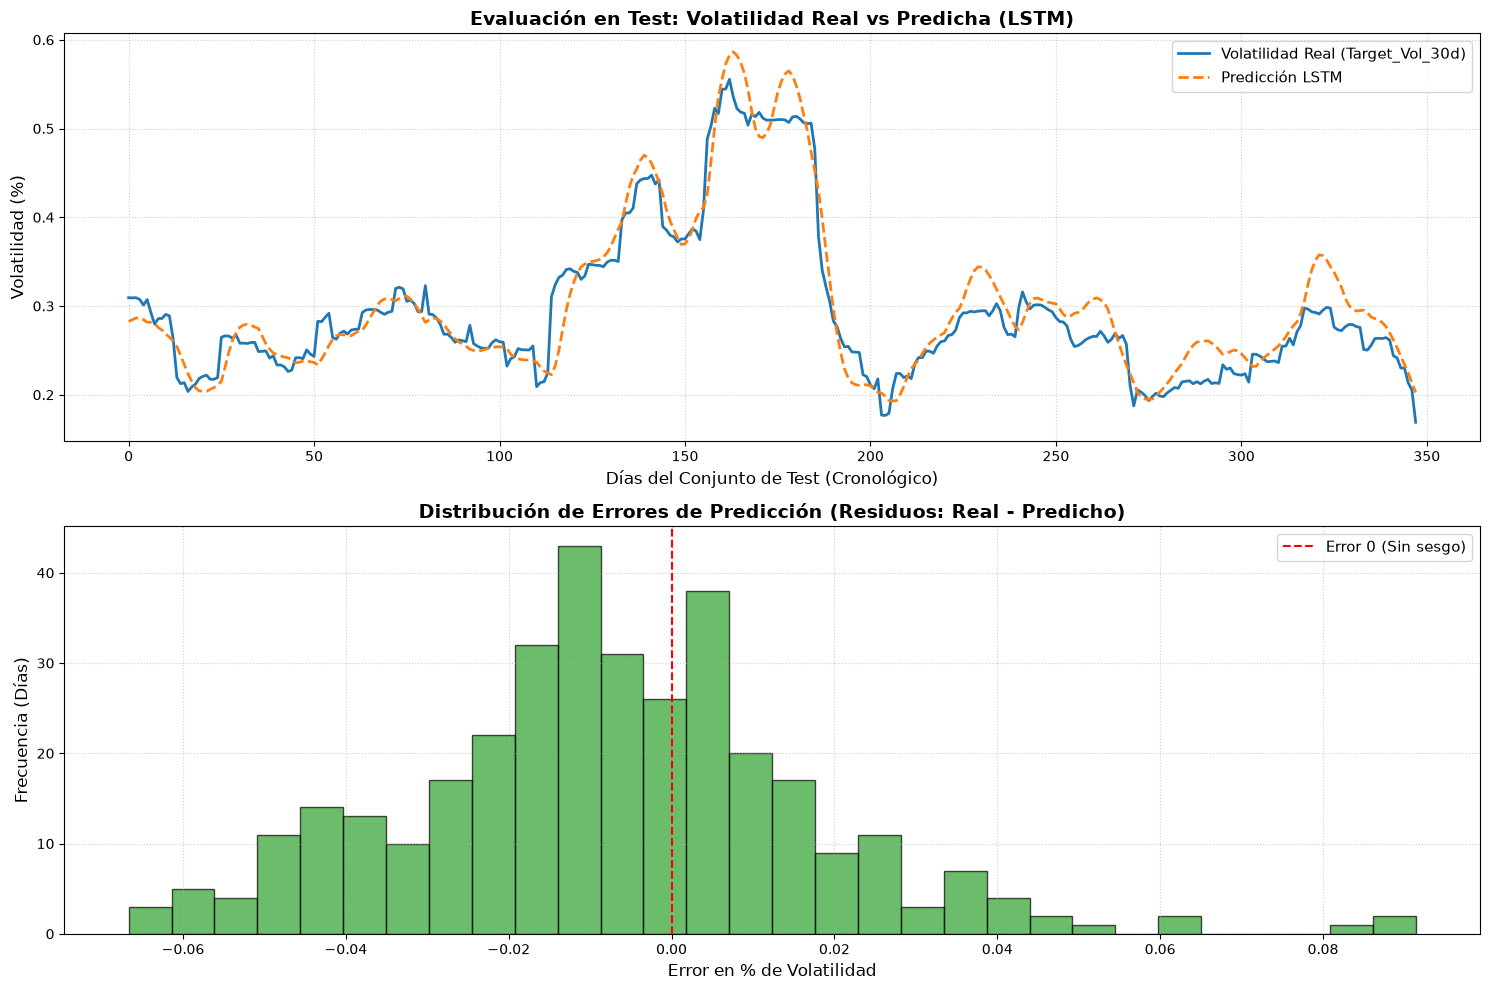

In [18]:
plt.figure(figsize=(15, 10))

# PLOT 1: REAL VOLATILITY VS PREDICTED
plt.subplot(2, 1, 1)
plt.plot(y_test_real, label='Real Volatility (Target_Vol_30d)', color='#1f77b4', linewidth=2)
plt.plot(y_pred_real, label='Prediction LSTM', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Evaluation on Test: Real Volatility vs Predicted (LSTM)', fontsize=14, fontweight='bold')
plt.xlabel('Days of Test set (Chronologic)', fontsize=12)
plt.ylabel('Volatility (%)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# PLOT 2: RESIDUAL HISTOGRAMS (ERRORS)
errores = y_test_real - y_pred_real

plt.subplot(2, 1, 2)
plt.hist(errores, bins=30, color='#2ca02c', edgecolor='black', alpha=0.7)
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Error 0 (No bias)')
plt.title('Prediction Error Distribution (Residuals: Actual - Predicted)', fontsize=14, fontweight='bold')
plt.xlabel('Volatility Error %', fontsize=12)
plt.ylabel('Frecuency (Days)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()